In [64]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [99]:
A = 0.22
r0 = 3.0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0
num_output_times = 101
dt0 = 0.005

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [100]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [101]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [102]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [ ]:
# initial_state = make_initial_state(A)

# Ham, Mom = get_constraints_diagnostic(
#     initial_state,
#     jnp.array([0.0]),
#     grid,
#     background,
#     matter,
# )

# # Exclude the ghost cells and the last two physical points,
# # where the outer boundary can affect the finite-difference stencil.
# interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

# ham_error = jnp.max(jnp.abs(Ham[0, interior]))
# mom_error = jnp.max(
#     jnp.linalg.norm(Mom[0, interior], axis=-1)
# )

# print("All initial-state values finite:",
#       bool(jnp.all(jnp.isfinite(initial_state))))
# print("All psi values positive:",
#       bool(jnp.all(solve_psi(r_physical, dr, A, r0, sigma) > 0)))
# print("Largest interior Hamiltonian constraint:", float(ham_error))
# print("Largest interior momentum constraint:", float(mom_error))

All initial-state values finite: True
All psi values positive: True
Largest interior Hamiltonian constraint: 0.0015155783133932025
Largest interior momentum constraint: 0.0


In [106]:
def evolve(amplitude):
    y0 = make_initial_state(amplitude)

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter)

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        central_lapse = state_grid[idx_lapse, NUM_GHOSTS]
        return central_lapse <= 5e-3

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        i0 = NUM_GHOSTS
        idx_u = matter.idx_u

        return (
            3.0 * state_grid[idx_u, i0]
            - 3.0 * state_grid[idx_u, i0 + 1]
            + state_grid[idx_u, i0 + 2]
        )
    save_times = jnp.linspace(0.0, T, num_output_times, endpoint=False)
    saveat = dfx.SaveAt(
        subs=[
            # Save full states at your usual output times for plots
            dfx.SubSaveAt(ts=save_times, t1=True),

            # Save only the central scalar at every solver step
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_scalar,
            ),
        ]
    )

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=T,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=1500,
    )

    return solution

def central_scalar_variation(amplitude):
    solution = evolve(amplitude)

    # The second save request contains the central scalar at each solver step.
    _, central_times = solution.ts
    _, central_u = solution.ys

    # Diffrax pads unused step slots with NaNs.
    valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
    u_clean = jnp.where(valid, central_u, 0.0)

    changes = jnp.abs(jnp.diff(u_clean))
    valid_pairs = valid[:-1] & valid[1:]

    # Add changes only when both consecutive saved values are real steps.
    return jnp.sum(jnp.where(valid_pairs, changes, 0.0))

In [107]:
L = central_scalar_variation(A)
print("L =", float(L))

L = 0.5191040492069523


In [108]:
amplitude = jnp.asarray(A, dtype=jnp.float64)

L, dL_dA = jax.jvp(
    central_scalar_variation,
    (amplitude,),
    (jnp.ones_like(amplitude),),
)

print("L =", float(L))
print("dL/dA =", float(dL_dA))

L = 0.5191040492069523
dL/dA = 2.9846126522277894


In [109]:
delta_A = 1e-4

L_plus = central_scalar_variation(A + delta_A)
L_minus = central_scalar_variation(A - delta_A)

dL_dA_fd = (L_plus - L_minus) / (2.0 * delta_A)

print("JAX derivative:", float(dL_dA))
print("Finite-difference derivative:", float(dL_dA_fd))

JAX derivative: 2.9846126522277894
Finite-difference derivative: 2.9931966469265436


In [110]:
b = -0.263
A_next = A - b / dL_dA

print("Current A:", float(A))
print("Suggested next A:", float(A_next))

Current A: 0.22
Suggested next A: 0.30811863737282297


In [111]:
solution_next = evolve(A_next)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_next))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

A: 0.30811863737282297
Collapse event fired: False
Last saved time: 6.0
Final central lapse: 0.8996642051954953


In [112]:
A_current = jnp.asarray(A_next, dtype=jnp.float64)

L_current, dL_current = jax.jvp(
    central_scalar_variation,
    (A_current,),
    (jnp.ones_like(A_current),),
)

print("A =", float(A_current))
print("L =", float(L_current))
print("dL/dA =", float(dL_current))

A = 0.30811863737282297
L = 0.864443992692085
dL/dA = 5.477774528817321


In [113]:
A_next = 0.41360717482782583

initial_state_next = make_initial_state(A_next)
print("Initial state is finite:",
      bool(jnp.all(jnp.isfinite(initial_state_next))))

Initial state is finite: True


In [114]:
solution_next = evolve(A_next)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_next))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

A: 0.41360717482782583
Collapse event fired: True
Last saved time: 5.595
Final central lapse: 0.00493671124650146


In [115]:
A_sub = 0.30811863737282297
A_proposed = 0.41360717482782583

A_trial = A_sub + 0.5 * (A_proposed - A_sub)
print("Trial amplitude:", A_trial)

solution_next = evolve(A_trial)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_trial))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

Trial amplitude: 0.3608629061003244
A: 0.3608629061003244
Collapse event fired: False
Last saved time: 6.0
Final central lapse: 0.7660154352269214


In [116]:
L_trial, dL_trial = jax.jvp(
    central_scalar_variation,
    (A_trial,),
    (jnp.ones_like(A_trial),),
)

print("A =", float(A_trial))
print("L =", float(L_trial))
print("dL/dA =", float(dL_trial))

A = 0.3608629061003244
L = 1.395837892343276
dL/dA = 21.54167374166251


In [123]:
def estimate_critical_amplitude(A1, dL_dA1, A2, dL_dA2):
    # Use the two gradients to estimate the scaling coefficient b.
    inv_d1 = 1.0 / dL_dA1
    inv_d2 = 1.0 / dL_dA2
    b_est = (A2 - A1) / (inv_d2 - inv_d1)

    # Use the second run to estimate the critical amplitude.
    A_critical_est = A2 - b_est / dL_dA2

    return b_est, A_critical_est


A1 = 0.3608629061003244
dL_dA1 = 21.54167374166251

A2 = 0.36985577912412837
dL_dA2 = 94.14741067231942

b_est, A_est = estimate_critical_amplitude(
    A1, dL_dA1, A2, dL_dA2
)

print("Estimated b:", float(b_est))
print("Estimated critical amplitude:", float(A_est))

Estimated b: -0.25119752020708536
Estimated critical amplitude: 0.3725239090112198


In [127]:

A_trial=0.38478137
solution_next = evolve(A_trial)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_trial))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

A: 0.38478137
Collapse event fired: True
Last saved time: 5.195
Final central lapse: 0.004916801894715014


In [119]:
L_trial, dL_trial = jax.jvp(
    central_scalar_variation,
    (A_trial,),
    (jnp.ones_like(A_trial),),
)

print("A =", float(A_trial))
print("L =", float(L_trial))
print("dL/dA =", float(dL_trial))

A = 0.3788486521479324
L = 1.3804340473697225
dL/dA = 43.57294320012079


In [120]:
A_sub = 0.3608629061003244
A_collapsed = 0.3788486521479324

A_trial = A_sub + 0.5 * (A_collapsed - A_sub)
print("Trial amplitude:", A_trial)

Trial amplitude: 0.36985577912412837


In [122]:
A_trial=0.36985577912412837
solution_next = evolve(A_trial)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_trial))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

L_trial, dL_trial = jax.jvp(
    central_scalar_variation,
    (A_trial,),
    (jnp.ones_like(A_trial),),
)

print("A =", float(A_trial))
print("L =", float(L_trial))
print("dL/dA =", float(dL_trial))

A: 0.36985577912412837
Collapse event fired: False
Last saved time: 6.0
Final central lapse: 0.628422579872072
A = 0.36985577912412837
L = 1.7945648543201607
dL/dA = 94.14741067231942


In [124]:
A_trial=0.3725239090112198
solution_next = evolve(A_trial)

# The outputs are grouped by the two SaveAt requests
plot_times, central_times = solution_next.ts
plot_states, central_u = solution_next.ys

# Find the last saved full state (Diffrax may pad after an early stop)
valid_times = jnp.isfinite(plot_times)
last_index = int(jnp.sum(valid_times)) - 1

last_state = plot_states[last_index].reshape(grid.NUM_VARS, grid.N)
final_central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A_trial))
print("Collapse event fired:", bool(solution_next.event_mask))
print("Last saved time:", float(plot_times[last_index]))
print("Final central lapse:", float(final_central_lapse))

L_trial, dL_trial = jax.jvp(
    central_scalar_variation,
    (A_trial,),
    (jnp.ones_like(A_trial),),
)

print("A =", float(A_trial))
print("L =", float(L_trial))
print("dL/dA =", float(dL_trial))

A: 0.3725239090112198
Collapse event fired: False
Last saved time: 6.0
Final central lapse: 0.15248968441546576
A = 0.3725239090112198
L = 1.6855145891491201
dL/dA = -584.3522916018995


In [125]:
A_check = jnp.asarray(0.3725239090112198, dtype=jnp.float64)
eps = 1e-5

L_minus = central_scalar_variation(A_check - eps)
L_plus = central_scalar_variation(A_check + eps)

dL_dA_finite_difference = (L_plus - L_minus) / (2.0 * eps)

print("JAX gradient:", float(dL_dA))
print("Finite-difference gradient:", float(dL_dA_finite_difference))

JAX gradient: 2.9846126522277894
Finite-difference gradient: -584.3321910674381


In [126]:
A_check = jnp.asarray(0.3725239090112198, dtype=jnp.float64)
eps = 1e-5

L_at_check, dL_ad_check = jax.jvp(
    central_scalar_variation,
    (A_check,),
    (jnp.ones_like(A_check),),
)

L_minus = central_scalar_variation(A_check - eps)
L_plus = central_scalar_variation(A_check + eps)
dL_fd_check = (L_plus - L_minus) / (2.0 * eps)

print("A:", float(A_check))
print("L:", float(L_at_check))
print("JAX gradient:", float(dL_ad_check))
print("Finite-difference gradient:", float(dL_fd_check))

A: 0.3725239090112198
L: 1.6855145891491201
JAX gradient: -584.3522916018995
Finite-difference gradient: -584.3321910674381


In [104]:
test_solution = evolve(A)

valid_rows = (
    jnp.isfinite(test_solution.ts)
    & jnp.all(jnp.isfinite(test_solution.ys), axis=1)
)

saved_times = test_solution.ts[valid_rows]
saved_states = test_solution.ys[valid_rows]

last_state = saved_states[-1].reshape(grid.NUM_VARS, grid.N)
central_lapse = last_state[idx_lapse, NUM_GHOSTS]

print("A:", float(A))
print("Collapse event fired:", bool(jnp.any(test_solution.event_mask)))
print("Last saved time:", float(saved_times[-1]))
print("Final central lapse:", float(central_lapse))

TypeError: isfinite requires ndarray or scalar arguments, got <class 'list'> at position 0.

In [96]:
state_history = saved_states.reshape(
    saved_states.shape[0],
    grid.NUM_VARS,
    grid.N,
)

central_lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]
lapse_changes = jnp.diff(central_lapse_history)

change_indices = jnp.arange(lapse_changes.size)
last_decrease_index = int(
    jnp.max(jnp.where(lapse_changes < 0, change_indices, -1))
)

if last_decrease_index >= 0:
    endpoint_index = last_decrease_index + 1

    print(
        "Last lapse decrease:",
        float(saved_times[last_decrease_index]),
        "to",
        float(saved_times[endpoint_index]),
    )
    print("Candidate endpoint:", float(saved_times[endpoint_index]))
    print(
        "Lapse is non-decreasing after it:",
        bool(jnp.all(lapse_changes[endpoint_index:] >= 0)),
    )
else:
    print("No lapse decrease found in this run.")

Last lapse decrease: 6.0 to 6.0
Candidate endpoint: 6.0
Lapse is non-decreasing after it: True


In [ ]:
amplitude = jnp.asarray(A, dtype=jnp.float64)

value, dvalue_dA = jax.jvp(
    central_scalar_variation,
    (amplitude,),
    (jnp.ones_like(amplitude),),
)

print("scalar variation:", value)
print("change in scalar variation per unit amplitude:", dvalue_dA)

scalar variation: 0.5812210805117896
change in scalar variation per unit amplitude: 3.5014710218353433


In [94]:
print("Current A:", float(A))

test_solution = evolve(A)
final_state = test_solution.ys[-1].reshape(grid.NUM_VARS, grid.N)

print("Collapse event triggered:", bool(jnp.any(test_solution.event_mask)))
print("Run ended at:", float(test_solution.t1))
print("Final central lapse:", float(final_state[idx_lapse, NUM_GHOSTS]))

Current A: 0.22
Collapse event triggered: False
Run ended at: 6.0
Final central lapse: 0.9603688355049093


In [81]:
delta = 1e-4

finite_difference = (
    central_scalar_variation(A + delta)
    - central_scalar_variation(A - delta)
) / (2 * delta)

print("JVP:", dvalue_dA)
print("finite difference:", finite_difference)

JVP: 2.694710011363311
finite difference: 2.6947014948197623


In [82]:
print("Current A:", A)

Current A: 0.24


In [73]:
for A_test in [A - 0.01, A, A + 0.01]:
    amplitude = jnp.asarray(A_test, dtype=jnp.float64)

    value, sensitivity = jax.jvp(
        central_scalar_variation,
        (amplitude,),
        (jnp.ones_like(amplitude),),
    )

    print(
        f"A={float(amplitude):.4f}: "
        f"variation={float(value):.6f}, "
        f"d(variation)/dA={float(sensitivity):.6f}"
    )

A=0.2300: variation=0.548692, d(variation)/dA=3.277391
A=0.2400: variation=0.581221, d(variation)/dA=3.501471
A=0.2500: variation=0.615405, d(variation)/dA=3.390462


Minimum innermost physical lapse: 0.5636554071139321


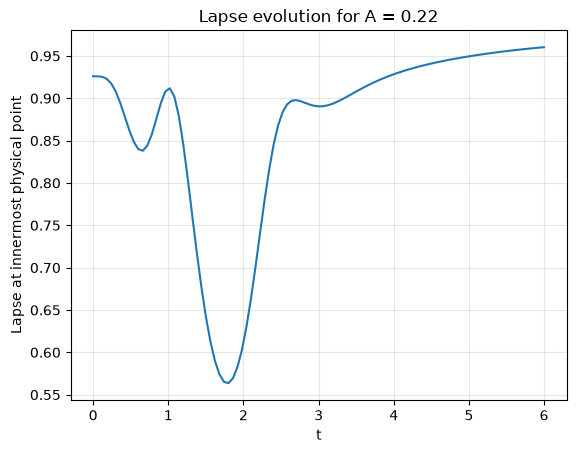

In [93]:
solution = evolve(A)

state_history = solution.ys.reshape(
    solution.ts.size,
    grid.NUM_VARS,
    grid.N,
)
lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]

print("Minimum innermost physical lapse:",
      float(jnp.min(lapse_history)))

plt.plot(solution.ts, lapse_history)
plt.xlabel("t")
plt.ylabel("Lapse at innermost physical point")
plt.title(f"Lapse evolution for A = {A:.2f}")
plt.grid(alpha=0.3)
plt.show()

In [74]:
central_lapse = state_history[:, idx_lapse, NUM_GHOSTS]
central_u = state_history[:, matter.idx_u, NUM_GHOSTS]

start = max(0, len(solution.ts) - 10)

for i in range(start, len(solution.ts)):
    print(
        f"t={float(solution.ts[i]):.2f}, "
        f"central lapse={float(central_lapse[i]):.6f}, "
        f"central scalar={float(central_u[i]):.6f}"
    )

print("Lapse changes over these saved times:")
print([float(x) for x in jnp.diff(central_lapse[start:])])

t=5.46, central lapse=0.955237, central scalar=0.000070
t=5.52, central lapse=0.955880, central scalar=0.000065
t=5.58, central lapse=0.956503, central scalar=0.000060
t=5.64, central lapse=0.957107, central scalar=0.000055
t=5.70, central lapse=0.957692, central scalar=0.000050
t=5.76, central lapse=0.958259, central scalar=0.000046
t=5.82, central lapse=0.958810, central scalar=0.000042
t=5.88, central lapse=0.959345, central scalar=0.000039
t=5.94, central lapse=0.959864, central scalar=0.000036
t=6.00, central lapse=0.960369, central scalar=0.000033
Lapse changes over these saved times:
[0.000643179737690347, 0.0006228822406384449, 0.0006035516236682081, 0.0005851246784620567, 0.0005675437378880321, 0.0005507559741433354, 0.0005347131898161273, 0.000519371015433423, 0.0005046887310299342]


In [77]:
lapse_changes = jnp.diff(central_lapse)
minimum_index = int(jnp.argmin(central_lapse))

print("Minimum central lapse:", float(central_lapse[minimum_index]))
print("Time of minimum:", float(solution.ts[minimum_index]))
print(
    "Lapse is non-decreasing after its minimum:",
    bool(jnp.all(lapse_changes[minimum_index:] >= 0)),
)

L_until_minimum = jnp.sum(
    jnp.abs(jnp.diff(central_u[:minimum_index + 1]))
)
print("Scalar total variation up to lapse minimum:", float(L_until_minimum))

Minimum central lapse: 0.5636554071139321
Time of minimum: 1.7999999999999998
Lapse is non-decreasing after its minimum: False
Scalar total variation up to lapse minimum: 0.3466694825585644


In [78]:
decrease_indices = jnp.where(lapse_changes < 0.0)[0]
last_decrease = int(decrease_indices[-1])
endpoint_index = last_decrease + 1

print(
    "Last lapse decrease:",
    f"t={float(solution.ts[last_decrease]):.2f} to "
    f"t={float(solution.ts[endpoint_index]):.2f}",
)
print("Candidate endpoint time:", float(solution.ts[endpoint_index]))
print(
    "Lapse stays non-decreasing afterward:",
    bool(jnp.all(lapse_changes[endpoint_index:] >= 0.0)),
)

L_subcritical = jnp.sum(
    jnp.abs(jnp.diff(central_u[:endpoint_index + 1]))
)
print("Subcritical total variation to candidate endpoint:", float(L_subcritical))

Last lapse decrease: t=2.94 to t=3.00
Candidate endpoint time: 3.0
Lapse stays non-decreasing afterward: True
Subcritical total variation to candidate endpoint: 0.4878768952686008


In [45]:
lapse_initial = state_history[0, idx_lapse]
lapse_final = state_history[-1, idx_lapse]

print("Maximum lapse change anywhere on grid:",
      float(jnp.max(jnp.abs(lapse_final - lapse_initial))))
print("Lapse change at innermost physical point:",
      float(lapse_final[NUM_GHOSTS] - lapse_initial[NUM_GHOSTS]))
print("Maximum change in the full state:",
      float(jnp.max(jnp.abs(solution.ys[-1] - solution.ys[0]))))

Maximum lapse change anywhere on grid: 0.04169415685805922
Lapse change at innermost physical point: 0.03440275276208882
Maximum change in the full state: 0.0832181726810981


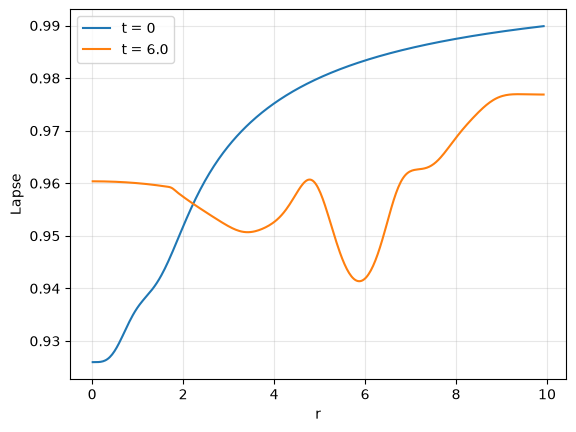

In [46]:
plt.plot(grid.r[physical], lapse_initial[physical], label="t = 0")
plt.plot(grid.r[physical], lapse_final[physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("Lapse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Maximum scalar-field change: 0.08088255944513496


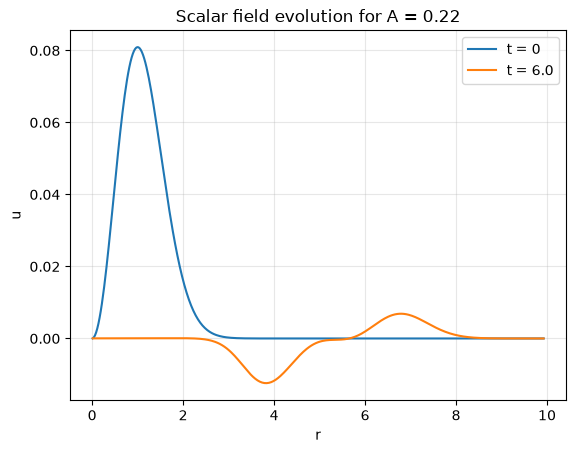

In [47]:
u_history = state_history[:, matter.idx_u, :]

print("Maximum scalar-field change:",
      float(jnp.max(jnp.abs(u_history[-1] - u_history[0]))))

plt.plot(grid.r[physical], u_history[0, physical], label="t = 0")
plt.plot(grid.r[physical], u_history[-1, physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("u")
plt.title(f"Scalar field evolution for A = {A:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Check that constraints are satisfied

In [48]:
Ham_history, Mom_history = get_constraints_diagnostic(
    solution.ys,
    solution.ts,
    grid,
    background,
    matter,
)

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)
mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

print("Largest interior Hamiltonian constraint at t=0:",
      float(ham_error[0]))
print("Largest interior Hamiltonian constraint at t=6:",
      float(ham_error[-1]))
print("Largest interior momentum constraint at t=6:",
      float(mom_error[-1]))

Largest interior Hamiltonian constraint at t=0: 0.0013118366889146933
Largest interior Hamiltonian constraint at t=6: 0.015216400685871162
Largest interior momentum constraint at t=6: 0.005587750336058574


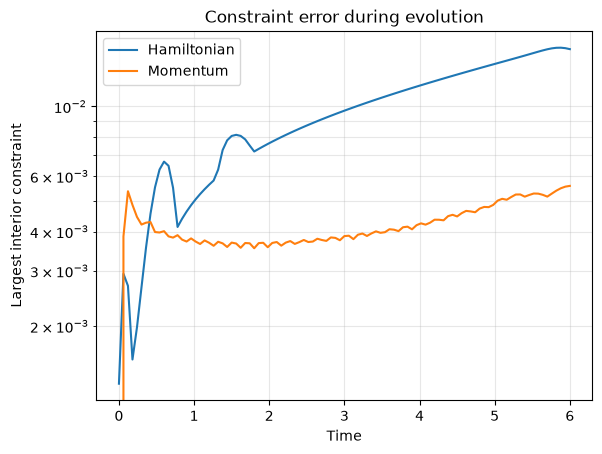

t=0.00: H=0.00131184, M=0
t=1.50: H=0.00805632, M=0.00368829
t=3.00: H=0.00969501, M=0.00386835
t=4.50: H=0.0126321, M=0.00446759
t=6.00: H=0.0152164, M=0.00558775


In [49]:
import matplotlib.pyplot as plt

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)

mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

plt.semilogy(solution.ts, ham_error, label="Hamiltonian")
plt.semilogy(solution.ts, mom_error, label="Momentum")
plt.xlabel("Time")
plt.ylabel("Largest interior constraint")
plt.title("Constraint error during evolution")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

for i in [0, 25, 50, 75, 100]:
    print(
        f"t={float(solution.ts[i]):.2f}: "
        f"H={float(ham_error[i]):.6g}, "
        f"M={float(mom_error[i]):.6g}"
    )

In [50]:
H0 = jnp.abs(Ham_history[0, interior])
local_i = int(jnp.argmax(H0))
i = local_i + NUM_GHOSTS

print("Initial H maximum:", float(H0[local_i]))
print("At r =", float(grid.r[i]))

Initial H maximum: 0.0013118366889146933
At r = 0.012578616352200613


In [ ]:
# print("dr =", float(dr))
# print("first physical radius =", float(r_physical[0]))
# print("radius / dr =", float(r_physical[0] / dr))

dr = 0.025157232704402514
first physical radius = 0.012578616352200613
radius / dr = 0.4999999999999744


In [ ]:
# state = make_initial_state(A).reshape(grid.NUM_VARS, grid.N)
# psi_physical = solve_psi(
#         r_physical, dr, 0.2, r0, sigma
#     )
# print(state[idx_lapse, physical][:5])
# print((psi_physical**-2)[:5])

[0.92596608 0.92596612 0.92596673 0.92596898 0.92597439]
[0.93853186 0.93853189 0.9385324  0.93853428 0.93853882]


0.0


In [ ]:
# h_final = Ham[-1, physical]
# m_final = Mom[-1, physical, :]

# print("last saved time:", solution.ts[-1])
# print("final state is finite:", jnp.all(jnp.isfinite(solution.ys[-1])))
# print("finite H values:", jnp.count_nonzero(jnp.isfinite(h_final)), "/", h_final.size)
# print("finite M values:", jnp.count_nonzero(jnp.isfinite(m_final)), "/", m_final.size)

last saved time: 6.0
final state is finite: True
finite H values: 395 / 395
finite M values: 1185 / 1185


In [ ]:
# final_grid = solution.ys[-1].reshape(grid.NUM_VARS, grid.N)

# for i, name in enumerate(state_vector.VARIABLE_NAMES):
#     bad_points = jnp.where(~jnp.isfinite(final_grid[i]))[0]
#     if bad_points.size > 0:
#         print(name, "bad grid points:", bad_points[:10])

In [ ]:
# print("max |H|:", jnp.max(jnp.abs(h_final)))
# print("max |M|:", jnp.max(jnp.abs(m_final)))

max |H|: 0.0013118366889146933
max |M|: 0.0


In [ ]:
# history = solution.ys.reshape(
#     solution.ts.size, grid.NUM_VARS, grid.N
# )

# bad_times = jnp.where(
#     ~jnp.all(jnp.isfinite(history), axis=(1, 2))
# )[0]
# if bad_times.size == 0:
#     print("All saved states are finite.")
# else:
#     print("First saved time with non-finite values:", solution.ts[bad_times[0]])

All saved states are finite.


In [ ]:
# idx_K = list(state_vector.VARIABLE_NAMES).index("K")
# idx_lapse = list(state_vector.VARIABLE_NAMES).index("lapse")
# for i, t_i in enumerate(solution.ts):
#     if t_i > 0.36:
#         break

#     state_i = history[i]
#     print(
#         f"t={float(t_i):.2f}",
#         "minimum lapse =", float(jnp.min(state_i[idx_lapse, physical])),
#         "maximum |K| =", float(jnp.max(jnp.abs(state_i[idx_K, physical]))),
#     )

t=0.00 minimum lapse = 0.9259660827428208 maximum |K| = 0.0
t=0.06 minimum lapse = 0.9259243381116998 maximum |K| = 0.0046407637114579126
t=0.12 minimum lapse = 0.9253326942484971 maximum |K| = 0.011053731297190707
t=0.18 minimum lapse = 0.9229949744741346 maximum |K| = 0.033322725197160126
t=0.24 minimum lapse = 0.9175270605987128 maximum |K| = 0.06723790643440743
t=0.30 minimum lapse = 0.9080378840478307 maximum |K| = 0.10604215301520667
t=0.36 minimum lapse = 0.8946667576819375 maximum |K| = 0.13935121019837174


In [ ]:
# print("minimum grid spacing:", float(grid.min_dr))
# print("recommended fixed dt:", 0.4 * float(grid.min_dr))

minimum grid spacing: 0.025157232704401622
recommended fixed dt: 0.01006289308176065


In [ ]:
# h_values = jnp.abs(Ham[-1, physical])
# h_local = int(jnp.argmax(h_values))
# h_grid = h_local + NUM_GHOSTS
# print("H maximum at r =", grid.r[h_grid])
# print("H value =", Ham[-1, h_grid])

# m_values = jnp.max(jnp.abs(Mom[-1, physical, :]), axis=-1)
# m_local = int(jnp.argmax(m_values))
# m_grid = m_local + NUM_GHOSTS
# print("M maximum at r =", grid.r[m_grid])
# print("M components =", Mom[-1, m_grid, :])

H maximum at r = 0.012578616352200613
H value = -0.0013118366889146933
M maximum at r = 0.012578616352200613
M components = [0. 0. 0.]


In [ ]:
# Ham, Mom = get_constraints_diagnostic(
#     solution.ys, solution.ts, grid, background, matter
# )

# h = Ham[-1, physical]
# m = Mom[-1, physical, :]

# print("last time:", solution.ts[-1])
# print("H shape:", Ham.shape, "M shape:", Mom.shape)
# print("max |H|:", jnp.max(jnp.abs(h)))
# print("max |M|:", jnp.max(jnp.abs(m)))

# h_local = int(jnp.argmax(jnp.abs(h)))
# m_local = int(jnp.argmax(jnp.max(jnp.abs(m), axis=-1)))
# print("H at its max:", h[h_local], "radius:", grid.r[h_local + NUM_GHOSTS])
# print("M at its max:", m[m_local], "radius:", grid.r[m_local + NUM_GHOSTS])

last time: 6.0
H shape: (101, 401) M shape: (101, 401, 3)
max |H|: 0.01848168795464149
max |M|: 0.005587750336058574
H at its max: -0.01848168795464149 radius: 9.89937106918239
M at its max: [-0.00558775  0.          0.        ] radius: 4.1886792452830175


In [ ]:
# r_physical = grid.r[physical]
# away_from_outer_edge = r_physical < 9.0

# h_bulk = jnp.abs(h[away_from_outer_edge])
# m_bulk = jnp.max(jnp.abs(m[away_from_outer_edge]), axis=-1)

# h_i = int(jnp.argmax(h_bulk))
# m_i = int(jnp.argmax(m_bulk))

# print("max |H| for r < 9:", h_bulk[h_i],
#       "at r =", r_physical[away_from_outer_edge][h_i])
# print("max |M| for r < 9:", m_bulk[m_i],
#       "at r =", r_physical[away_from_outer_edge][m_i])

max |H| for r < 9: 0.0025522872404521516 at r = 0.012578616352200613
max |M| for r < 9: 0.005587750336058574 at r = 4.1886792452830175
